# 03 — Modelling & Hyperparameter Tuning

**Training set only.** The test set (20% of lots) stays sealed until `04_evaluation.ipynb`.

Plan
1. Set up lot-grouped cross-validation on the training set.
2. Compare models of increasing complexity: majority-class baseline → logistic regression → Random Forest → LightGBM.
3. Tune the best model with randomized search + grouped CV.
4. Refit the tuned model on the full training set and save it.

**Primary metric: macro-F1** — the average F1 over all 9 classes, so the rare defect types count as much as `none`.
Supporting metrics: defect recall (share of real defects flagged as *some* defect), worst-class recall, accuracy
(shown only to illustrate why it misleads).

In [1]:
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, spearmanr, uniform
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", message="X does not have valid feature names")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import FEATURE_NAMES

sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
CLASS_ORDER = ["none", "Edge-Ring", "Edge-Loc", "Center", "Loc",
               "Scratch", "Random", "Donut", "Near-full"]
RANDOM_STATE = 42

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
feats = pd.read_parquet(ROOT / "data" / "features.parquet")
train = feats[feats["split"] == "train"].reset_index(drop=True)   # test rows are not touched here
X, y, groups = train[FEATURE_NAMES], train["failureType"], train["lotName"]
print(f"Training set: {len(train):,} wafers, {groups.nunique():,} lots, {X.shape[1]} features")
y.value_counts().reindex(CLASS_ORDER).to_frame("train count").T

Training set: 138,365 wafers, 8,601 lots, 69 features


failureType,none,Edge-Ring,Edge-Loc,Center,Loc,Scratch,Random,Donut,Near-full
train count,117951,7744,4151,3435,2874,954,693,444,119


## Cross-validation setup

`StratifiedGroupKFold(5)`: every fold keeps whole lots together (no lot in both the fitting and validation part)
and keeps the class mix similar. All models use **the same folds**, so the comparison is fair.

Scores below are **out-of-fold**: each training wafer is predicted by a model that never saw its lot.

In [3]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def score(y_true, y_pred):
    defect_true, defect_pred = y_true != "none", y_pred != "none"
    per_class_recall = recall_score(y_true, y_pred, labels=CLASS_ORDER, average=None, zero_division=0)
    worst = int(np.argmin(per_class_recall))
    return {
        "macro_F1": f1_score(y_true, y_pred, average="macro"),
        "weighted_F1": f1_score(y_true, y_pred, average="weighted"),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "defect_recall": recall_score(defect_true, defect_pred),
        "defect_precision": precision_score(defect_true, defect_pred, zero_division=0),
        "worst_class": f"{CLASS_ORDER[worst]} ({per_class_recall[worst]:.2f})",
    }

def evaluate(name, model):
    t0 = time.time()
    pred = cross_val_predict(model, X, y, groups=groups, cv=cv)
    row = {"model": name, **score(y, pred), "cv_time_s": round(time.time() - t0)}
    per_class = pd.Series(f1_score(y, pred, labels=CLASS_ORDER, average=None), index=CLASS_ORDER, name=name)
    return row, per_class, pred

## Models of increasing complexity

| # | Model | Why it's included |
|---|---|---|
| 0 | Majority class (always `none`) | Naive baseline — what you get with no model |
| 1 | Logistic regression (scaled, balanced class weights) | Simple, interpretable linear model |
| 2 | Random Forest (300 trees, balanced class weights) | Nonlinear, robust, little tuning needed |
| 3 | LightGBM (gradient boosting, balanced class weights) | Usually strongest on tabular features |

Class weights make mistakes on rare classes cost more during training (EDA insight 1).
`StandardScaler` sits inside the pipeline, so it is re-fit on each training fold only.

In [4]:
models = {
    "0 Majority class": DummyClassifier(strategy="most_frequent"),
    "1 Logistic regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "2 Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE),
    "3 LightGBM": LGBMClassifier(
        n_estimators=400, learning_rate=0.05, num_leaves=31, class_weight="balanced",
        n_jobs=-1, verbose=-1, random_state=RANDOM_STATE),
}

rows, per_class_f1, oof_preds = [], [], {}
for name, model in models.items():
    row, pc, pred = evaluate(name, model)
    rows.append(row); per_class_f1.append(pc); oof_preds[name] = pred
    print(f"{name:24s} macro-F1 {row['macro_F1']:.3f}  ({row['cv_time_s']}s)")

0 Majority class         macro-F1 0.102  (4s)


1 Logistic regression    macro-F1 0.756  (97s)


2 Random Forest          macro-F1 0.868  (119s)


3 LightGBM               macro-F1 0.894  (93s)


## Hyperparameter tuning — LightGBM (the best untuned model)


- **Method:** `RandomizedSearchCV`, 25 random configurations, scored by macro-F1 with
  `StratifiedGroupKFold(3)` on the training set (3 folds instead of 5 to keep runtime reasonable).
- Random search instead of grid search: with 8 hyperparameters a grid would need thousands of fits; random
  search covers the space well with far fewer.
- `class_weight` is itself a hyperparameter (balanced vs none) so we can measure how much it matters.
- The search takes ~40 min, so its results are cached in `reports/tuning_results.csv`.
  Delete that file to re-run it.


In [5]:

param_dist = {
    "n_estimators": randint(200, 800),
    "learning_rate": loguniform(0.02, 0.2),
    "num_leaves": randint(15, 128),
    "min_child_samples": randint(5, 100),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.4, 0.6),
    "reg_lambda": loguniform(1e-3, 10),
    "class_weight": [None, "balanced"],
}
TUNING_CSV = ROOT / "reports" / "tuning_results.csv"

if TUNING_CSV.exists():
    res = pd.read_csv(TUNING_CSV)
    print(f"Loaded cached search results ({len(res)} configurations) from {TUNING_CSV.name}")
else:
    search = RandomizedSearchCV(
        LGBMClassifier(subsample_freq=1, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE),
        param_dist, n_iter=25, scoring="f1_macro",
        cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE, return_train_score=True, refit=False, n_jobs=1,
    )
    t0 = time.time()
    search.fit(X, y, groups=groups)
    print(f"Search took {(time.time() - t0) / 60:.1f} min")
    res = pd.DataFrame(search.cv_results_).rename(columns=lambda c: c.replace("param_", ""))
    res["train_val_gap"] = res["mean_train_score"] - res["mean_test_score"]
    cols = list(param_dist) + ["mean_test_score", "std_test_score", "mean_train_score",
                               "train_val_gap", "mean_fit_time"]
    res = res[cols].sort_values("mean_test_score", ascending=False).reset_index(drop=True)
    res.to_csv(TUNING_CSV, index=False)

res["class_weight"] = res["class_weight"].fillna("none")
res.round(4)


Loaded cached search results (25 configurations) from tuning_results.csv


,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,class_weight,mean_test_score,std_test_score,mean_train_score,train_val_gap,mean_fit_time
0,710,0.0466,126,74,0.6603,0.8369,1.5609,none,0.8949,0.0067,0.9999,0.1051,47.7065
1,470,0.0792,86,52,0.8083,0.9369,0.1913,balanced,0.8944,0.0073,0.9999,0.1056,21.9108
2,676,0.0662,77,8,0.7799,0.5870,2.3396,balanced,0.8943,0.0053,0.9999,0.1057,24.9279
3,704,0.0482,17,68,0.8721,0.7710,2.7527,none,0.8939,0.0039,0.9999,0.1061,17.0277
4,430,0.0265,76,93,0.6912,0.5946,0.0028,none,0.8920,0.0036,0.9999,0.1079,15.2531
5,360,0.0304,90,25,0.6028,0.5274,0.2796,balanced,0.8897,0.0043,0.9984,0.1087,13.2935
6,558,0.0450,84,7,0.7670,0.4003,0.1104,balanced,0.8886,0.0065,0.9999,0.1114,21.4013
7,227,0.0395,122,10,0.9570,0.7746,0.0056,balanced,0.8884,0.0062,0.9999,0.1115,21.8374
8,295,0.1573,18,56,0.6997,0.5210,4.2684,none,0.8880,0.0035,0.9999,0.1119,6.2001
9,746,0.0423,79,48,0.9887,0.5866,0.0340,none,0.8879,0.0060,0.9999,0.1120,28.1585



### Which hyperparameter mattered most?

Two configurations **diverged** (macro-F1 0.69 and 0.22) — both combined near-zero L2 regularisation
(`reg_lambda` ≈ 0.001) with no class weights. The effect ranking is therefore shown for all runs *and* for the
23 stable runs only, so the two failures don't dominate the conclusion.


2 diverged runs:


,learning_rate,reg_lambda,class_weight,mean_test_score
23,0.0798,0.0017,none,0.6909
24,0.1778,0.0012,none,0.2181


,|spearman| all runs,|spearman| stable runs
reg_lambda,0.482,0.341
min_child_samples,0.125,0.188
learning_rate,0.087,0.157
n_estimators,0.286,0.143
colsample_bytree,0.110,0.124
subsample,0.013,0.043
num_leaves,0.200,0.043


,mean,max,count
class_weight (stable runs),,,
balanced,0.8866,0.8944,10
none,0.8833,0.8949,13


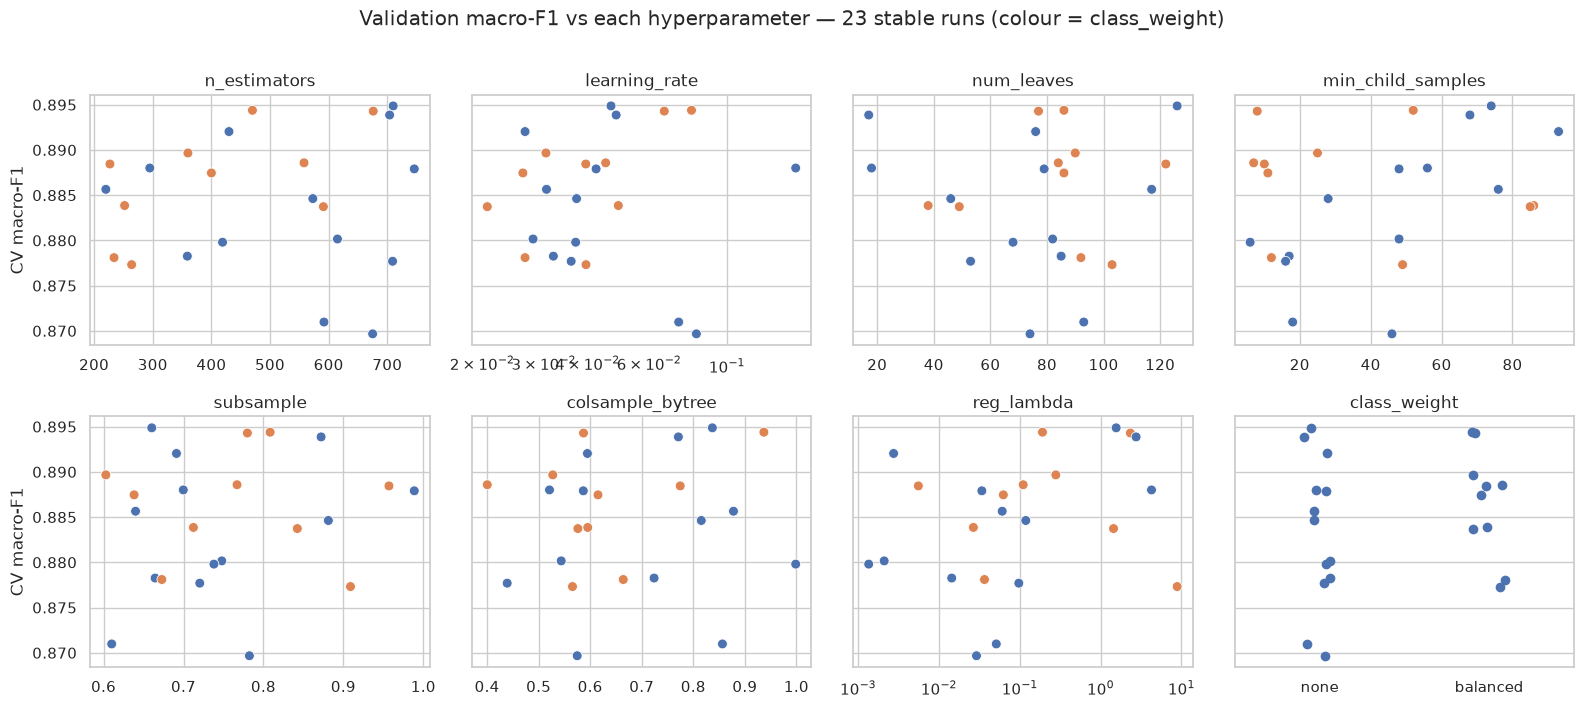

In [6]:

numeric = [p for p in param_dist if p != "class_weight"]
stable = res[res["mean_test_score"] >= 0.8]
print(f"{len(res) - len(stable)} diverged runs:")
display(res.loc[res["mean_test_score"] < 0.8, ["learning_rate", "reg_lambda", "class_weight", "mean_test_score"]].round(4))

effect_tbl = pd.DataFrame({
    "|spearman| all runs": {p: abs(spearmanr(res[p], res["mean_test_score"]).statistic) for p in numeric},
    "|spearman| stable runs": {p: abs(spearmanr(stable[p], stable["mean_test_score"]).statistic) for p in numeric},
}).sort_values("|spearman| stable runs", ascending=False)
display(effect_tbl.round(3))
display(stable.groupby("class_weight")["mean_test_score"].agg(["mean", "max", "count"]).round(4)
        .rename_axis("class_weight (stable runs)"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, p in zip(axes.flat, list(param_dist)):
    if p == "class_weight":
        sns.stripplot(data=stable, x="class_weight", y="mean_test_score", ax=ax, size=7)
    else:
        sns.scatterplot(data=stable, x=p, y="mean_test_score", hue="class_weight", ax=ax, s=50, legend=False)
        if p in ("learning_rate", "reg_lambda"):
            ax.set_xscale("log")
    ax.set(title=p, xlabel="", ylabel="CV macro-F1")
fig.suptitle("Validation macro-F1 vs each hyperparameter — 23 stable runs (colour = class_weight)", y=1.01)
plt.tight_layout(); savefig("tuning_effects"); plt.show()



**Findings**
- **`reg_lambda` (L2 regularisation) had the biggest effect** — strongest relationship with the score both with
  and without the diverged runs. Why: each boosting round adds 9 trees (one per class); for rare classes with
  few examples, leaf values can become extreme. With almost no regularisation and a higher learning rate those
  extreme values compound and training collapses. Moderate regularisation keeps the rare-class trees stable.
- **The search landscape is flat** among stable runs (≈0.87–0.895): the top 4 configurations are within one
  standard deviation of each other (±0.007). Tuning gains over the untuned LightGBM are small (~+0.005).
- **`class_weight` barely moves macro-F1** (0.887 vs 0.883 on stable runs) but, as shown below, it shifts the
  **precision/recall balance** — which matters to the business.
- Every configuration scores ~1.00 on the training folds (gap ≈ 0.10): the trees memorise the training wafers,
  so the *validation* score is the only trustworthy one.



## Model selection — re-check the shortlist on all 5 folds

Because the top configurations are statistically tied on 3-fold macro-F1, the top 3 are re-evaluated on the
same 5 folds as the other models. Selection rule (decided before looking at the test set):
**highest 5-fold macro-F1; if within 0.005, prefer higher defect recall** (a missed defect means a faulty tool
keeps running, which costs more than a false alarm).


In [7]:

def to_params(r):
    return {
        "n_estimators": int(r["n_estimators"]), "learning_rate": float(r["learning_rate"]),
        "num_leaves": int(r["num_leaves"]), "min_child_samples": int(r["min_child_samples"]),
        "subsample": float(r["subsample"]), "colsample_bytree": float(r["colsample_bytree"]),
        "reg_lambda": float(r["reg_lambda"]),
        "class_weight": None if r["class_weight"] == "none" else r["class_weight"],
    }

shortlist = []
for rank, r in res.head(3).iterrows():
    params = to_params(r)
    model = LGBMClassifier(**params, subsample_freq=1, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE)
    row, pc, pred = evaluate(f"search rank {rank}", model)
    shortlist.append({"rank": rank, "params": params, "row": row, "per_class": pc, "pred": pred})
    print(f"rank {rank} (class_weight={r['class_weight']}): macro-F1 {row['macro_F1']:.4f}, "
          f"defect recall {row['defect_recall']:.4f}, defect precision {row['defect_precision']:.4f}")

best_f1 = max(s["row"]["macro_F1"] for s in shortlist)
contenders = [s for s in shortlist if s["row"]["macro_F1"] >= best_f1 - 0.005]
chosen = max(contenders, key=lambda s: (s["row"]["defect_recall"], s["row"]["macro_F1"]))
best_params = chosen["params"]
print(f"\nSelected search rank {chosen['rank']}:", best_params)

chosen["row"]["model"] = "4 LightGBM (tuned)"
rows.append(chosen["row"]); per_class_f1.append(chosen["per_class"].rename("4 LightGBM (tuned)"))
oof_preds["4 LightGBM (tuned)"] = chosen["pred"]
pd.DataFrame([{**s["row"], "model": f"search rank {s['rank']}"} for s in shortlist]).set_index("model").round(4)


rank 0 (class_weight=none): macro-F1 0.8970, defect recall 0.9288, defect precision 0.9715


rank 1 (class_weight=balanced): macro-F1 0.8993, defect recall 0.9485, defect precision 0.9532


rank 2 (class_weight=balanced): macro-F1 0.8962, defect recall 0.9513, defect precision 0.9484

Selected search rank 2: {'n_estimators': 676, 'learning_rate': 0.06623659776144764, 'num_leaves': 77, 'min_child_samples': 8, 'subsample': 0.7799016533479063, 'colsample_bytree': 0.5870266456536466, 'reg_lambda': 2.339586455122247, 'class_weight': 'balanced'}


,macro_F1,weighted_F1,accuracy,balanced_acc,defect_recall,defect_precision,worst_class,cv_time_s
model,,,,,,,,
search rank 0,0.8970,0.9793,0.9799,0.8781,0.9288,0.9715,Scratch (0.71),234
search rank 1,0.8993,0.9796,0.9797,0.8976,0.9485,0.9532,Scratch (0.75),182
search rank 2,0.8962,0.9792,0.9792,0.8970,0.9513,0.9484,Scratch (0.75),215


## Results — all models side by side (5-fold grouped CV on the training set)

In [8]:
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(ROOT / "reports" / "model_comparison.csv")
comparison.style.format({c: "{:.3f}" for c in comparison.columns
                         if c not in ("worst_class", "cv_time_s")}).background_gradient(
    subset=["macro_F1", "defect_recall"], cmap="Greens")

,macro_F1,weighted_F1,accuracy,balanced_acc,defect_recall,defect_precision,worst_class,cv_time_s
model,,,,,,,,
0 Majority class,0.102,0.785,0.852,0.111,0.000,0.000,Edge-Ring (0.00),4
1 Logistic regression,0.756,0.933,0.921,0.903,0.986,0.688,Loc (0.75),97
2 Random Forest,0.868,0.972,0.973,0.830,0.882,0.975,Scratch (0.56),119
3 LightGBM,0.894,0.977,0.977,0.902,0.965,0.925,Scratch (0.78),93
4 LightGBM (tuned),0.896,0.979,0.979,0.897,0.951,0.948,Scratch (0.75),215


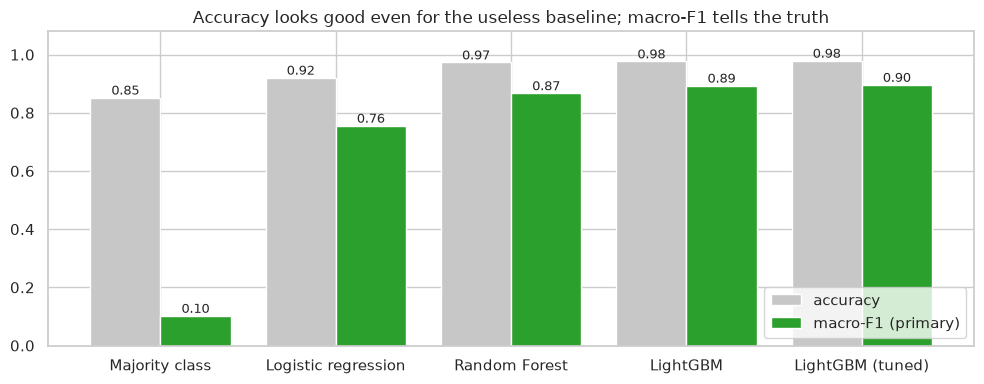

In [9]:
plot_df = comparison.reset_index()
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(plot_df))
ax.bar(x - 0.2, plot_df["accuracy"], 0.4, label="accuracy", color="#c7c7c7")
ax.bar(x + 0.2, plot_df["macro_F1"], 0.4, label="macro-F1 (primary)", color="#2ca02c")
for i, (a, f) in enumerate(zip(plot_df["accuracy"], plot_df["macro_F1"])):
    ax.text(i - 0.2, a + 0.01, f"{a:.2f}", ha="center", fontsize=9)
    ax.text(i + 0.2, f + 0.01, f"{f:.2f}", ha="center", fontsize=9)
ax.set_xticks(x, [m.split(" ", 1)[1] for m in plot_df["model"]])
ax.set(ylim=(0, 1.08), title="Accuracy looks good even for the useless baseline; macro-F1 tells the truth")
ax.legend(loc="lower right")
plt.tight_layout(); savefig("model_comparison"); plt.show()

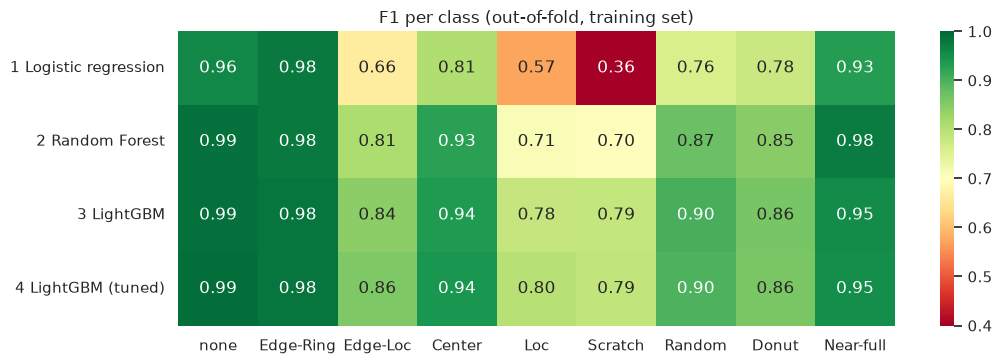

In [10]:
pcf = pd.concat(per_class_f1, axis=1).T
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(pcf.drop(index="0 Majority class"), annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.4, vmax=1, ax=ax)
ax.set(title="F1 per class (out-of-fold, training set)", ylabel="")
plt.tight_layout(); savefig("per_class_f1"); plt.show()

## Final model — refit on the full training set, feature importance

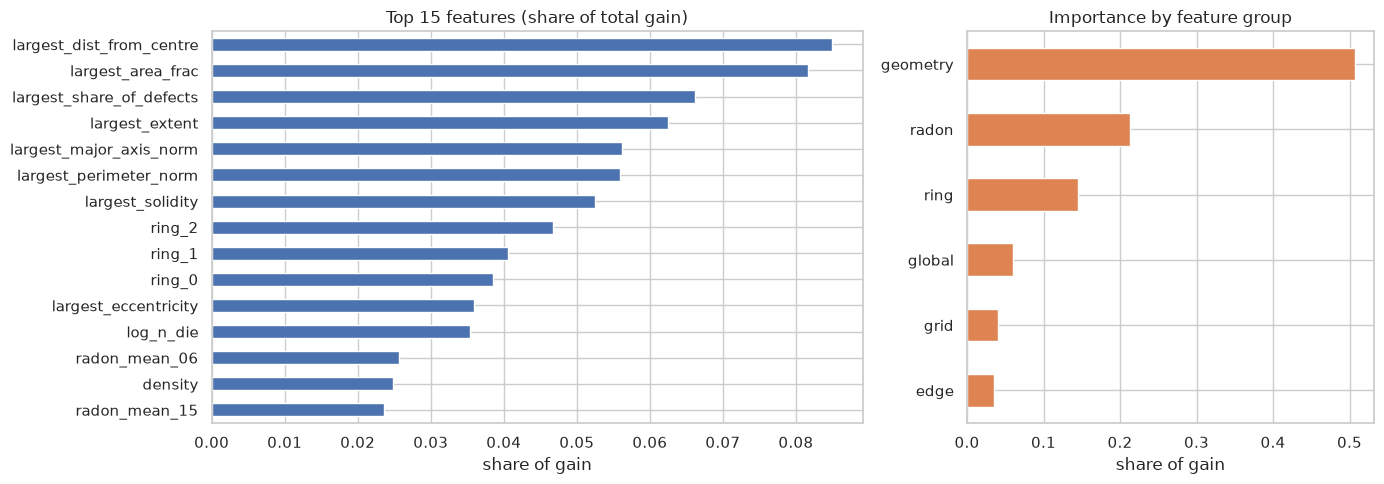

geometry    0.507
radon       0.212
ring        0.145
global      0.060
grid        0.040
edge        0.036
dtype: float64

In [11]:

final_model = LGBMClassifier(**best_params, subsample_freq=1, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE)
final_model.fit(X, y)

imp = pd.Series(final_model.booster_.feature_importance("gain"), index=FEATURE_NAMES)
imp = (imp / imp.sum()).sort_values(ascending=False)

group_of = lambda f: ("radon" if f.startswith("radon") else "grid" if f.startswith("grid")
                      else "ring" if f.startswith("ring") else "edge" if f.startswith("edge")
                      else "geometry" if f.startswith(("largest", "n_clusters")) else "global")
by_group = imp.groupby(imp.index.map(group_of)).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.6, 1]})
imp.head(15)[::-1].plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set(title="Top 15 features (share of total gain)", xlabel="share of gain")
by_group[::-1].plot.barh(ax=axes[1], color="#dd8452")
axes[1].set(title="Importance by feature group", xlabel="share of gain")
plt.tight_layout(); savefig("feature_importance"); plt.show()
by_group.round(3)


In [12]:

joblib.dump({"model": final_model, "features": FEATURE_NAMES, "classes": list(final_model.classes_),
             "best_params": best_params, "cv_macro_f1": chosen["row"]["macro_F1"]},
            MODEL_DIR / "lgbm_tuned.joblib")
pd.DataFrame({"lotName": groups, "y_true": y, **{k: v for k, v in oof_preds.items()}}).to_parquet(
    ROOT / "data" / "oof_predictions.parquet", index=False)
print("Saved models/lgbm_tuned.joblib and data/oof_predictions.parquet")


Saved models/lgbm_tuned.joblib and data/oof_predictions.parquet
